Title. DCA vs. Lump-Sum Investing

Assumptions: 

Week 1 - collect data

In [2]:
import yfinance as yf
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
from pandas_datareader import data as pdr

In [4]:
tesla_stock = yf.download("TSLA", start = "2016-01-01", end = "2026-01-01", auto_adjust=False )

[*********************100%***********************]  1 of 1 completed


In [5]:
tesla_stock.head()


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,,
2016-01-04,14.894000,14.894000,15.425333,14.600000,15.381333,102406500
2016-01-05,14.895333,14.895333,15.126000,14.666667,15.090667,47802000
2016-01-06,14.602667,14.602667,14.670000,14.398667,14.666667,56686500
2016-01-07,14.376667,14.376667,14.562667,14.244667,14.279333,53314500
2016-01-08,14.066667,14.066667,14.696000,14.051333,14.524000,54421500


.head() method shows first 5 data points of the tesla stock but does not show daily returns which is necessary for determining lump sum vs DCA

In [6]:
tesla_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,,
2025-12-24,485.399994,485.399994,490.899994,476.799988,488.480011,41285400
2025-12-26,475.190002,475.190002,489.089996,473.820007,485.230011,58780700
2025-12-29,459.640015,459.640015,469.399994,459.000000,469.000000,66263000
2025-12-30,454.429993,454.429993,463.119995,453.829987,461.089996,59238500
2025-12-31,449.720001,449.720001,456.549988,449.299988,456.100006,49078000


.tail() is similar to .head() but it shows last 5 data points

In [7]:
tesla_stock["Daily Returns"] = tesla_stock["Adj Close"].pct_change()
tesla_stock.head()

Price,Adj Close,Close,High,Low,Open,Volume,Daily Returns
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,TSLA,
Date,,,,,,,
2016-01-04,14.894000,14.894000,15.425333,14.600000,15.381333,102406500,NaN
2016-01-05,14.895333,14.895333,15.126000,14.666667,15.090667,47802000,0.000090
2016-01-06,14.602667,14.602667,14.670000,14.398667,14.666667,56686500,-0.019648
2016-01-07,14.376667,14.376667,14.562667,14.244667,14.279333,53314500,-0.015477
2016-01-08,14.066667,14.066667,14.696000,14.051333,14.524000,54421500,-0.021563


pct_change is a method in pandas that calculates percentage change. It takes (current days value - previous day value)/ previous day value showing how much percentage you would make per day. 

In [8]:
tesla_stock["Daily Returns"] = tesla_stock["Adj Close"].pct_change()
tesla_stock.tail()

Price,Adj Close,Close,High,Low,Open,Volume,Daily Returns
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,TSLA,
Date,,,,,,,
2025-12-24,485.399994,485.399994,490.899994,476.799988,488.480011,41285400,-0.000330
2025-12-26,475.190002,475.190002,489.089996,473.820007,485.230011,58780700,-0.021034
2025-12-29,459.640015,459.640015,469.399994,459.000000,469.000000,66263000,-0.032724
2025-12-30,454.429993,454.429993,463.119995,453.829987,461.089996,59238500,-0.011335
2025-12-31,449.720001,449.720001,456.549988,449.299988,456.100006,49078000,-0.010365


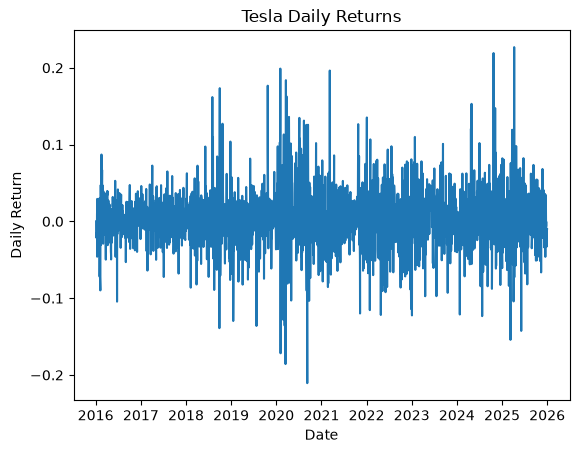

In [9]:
plt.plot(tesla_stock["Daily Returns"])
plt.title("Tesla Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

(technically not apart of week 1 but added) DAILY RETURNS


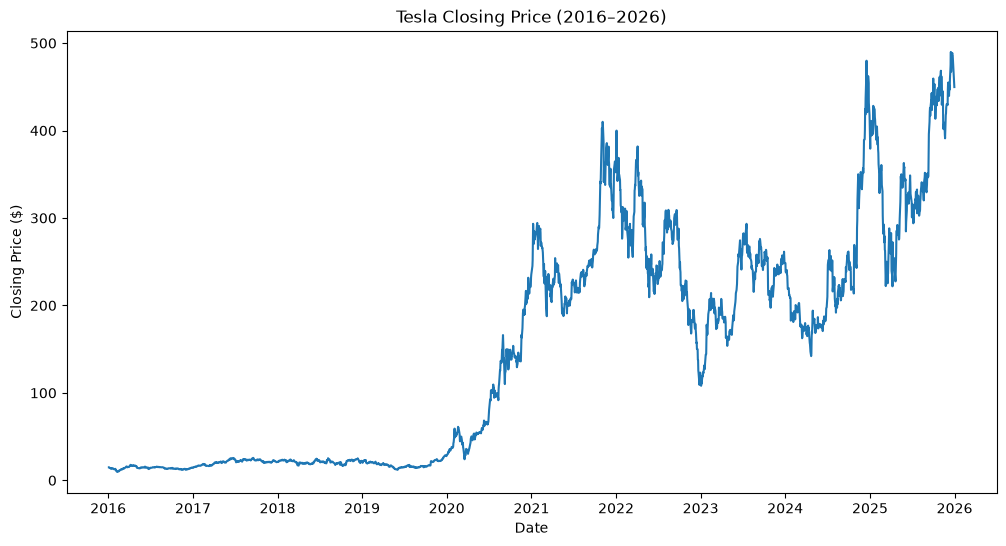

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(tesla_stock["Close"])

plt.title("Tesla Closing Price (2016–2026)")
plt.xlabel("Date")
plt.ylabel("Closing Price ($)")

plt.show()

This plots the closing prices of the stock 

In [12]:
tesla_stock.isna().sum()

Price          Ticker
Adj Close      TSLA      0
Close          TSLA      0
High           TSLA      0
Low            TSLA      0
Open           TSLA      0
Volume         TSLA      0
Daily Returns            1
dtype: int64

In [13]:
print("Number of trading days:", len(tesla_stock))
print("Start date:", tesla_stock.index.min())
print("End date:", tesla_stock.index.max())

Number of trading days: 2514
Start date: 2016-01-04 00:00:00
End date: 2025-12-31 00:00:00


Checks for missing values - weekends and market holidays are not included

Week 2 - simulation 

Lump-Sum Investment

The lump-sum strategy invests the entire investment amount on the first available trading day of the selected period. The number of shares purchased remains constant, while portfolio value changes with the stock price.

In [14]:
def lump_sum_investment(prices, investment_amount):
    first_price = prices.iloc[0]
    
    shares = investment_amount / first_price
    
    portfolio_value = shares * prices
    
    return portfolio_value

Sets up the lump sum function

In [15]:
test_data = tesla_stock["Close"].loc["2020-01-01":"2020-04-01"]

lump_sum = lump_sum_investment(test_data, 10000)

lump_sum.head()

Ticker,TSLA
Date,
2020-01-02,10000.000000
2020-01-03,10296.332583
2020-01-06,10494.584730
2020-01-07,10901.780123
2020-01-08,11438.200315


In [16]:
lump_sum.tail()

Ticker,TSLA
Date,
2020-03-26,12275.368372
2020-03-27,11954.632711
2020-03-30,11670.385633
2020-03-31,12178.683005
2020-04-01,11192.302355


In [17]:
print("Starting value:", 10000)
print("Ending value:", lump_sum.iloc[-1])

Starting value: 10000
Ending value: Ticker
TSLA    11192.302355
Name: 2020-04-01 00:00:00, dtype: float64


Test data over a 3 month period (january 2020-april 2020)

DCA function - investment strategy where you invest a fixed amount of money at regular intervals—such as weekly or monthly—regardless of the asset's price or market conditions (in this case monthly)

In [ ]:
def dca_investment(prices, investment_amount):
    # Make sure the index is made up of dates
    prices.index = pd.to_datetime(prices.index)
    
    # Find the first trading day of each month
    monthly_dates = prices.groupby(
        prices.index.to_period("M")
    ).head(1).index
    
    # Divide investment equally across months
    monthly_amount = investment_amount / len(monthly_dates)
    
    shares = 0
    portfolio_values = []
    
    for date, price in prices.items():
        if date in monthly_dates:
            shares += monthly_amount / price
        
        portfolio_values.append(shares * price)
    
    return pd.Series(portfolio_values, index=prices.index)

Test DCA function

In [30]:
test_data = tesla_stock[("Close", "TSLA")].loc["2020-01-01":"2020-12-31"]

In [31]:
print(type(test_data))
print(test_data.head())

<class 'pandas.Series'>
Date
2020-01-02    28.684000
2020-01-03    29.534000
2020-01-06    30.102667
2020-01-07    31.270666
2020-01-08    32.809334
Name: (Close, TSLA), dtype: float64


In [32]:
investment = 12000

lump_sum = lump_sum_investment(test_data, investment)
dca = dca_investment(test_data, investment)

print("Lump Sum Ending Value:", lump_sum.iloc[-1])
print("DCA Ending Value:", dca.iloc[-1])

Lump Sum Ending Value: 98406.07760908756
DCA Ending Value: 45311.575498547856


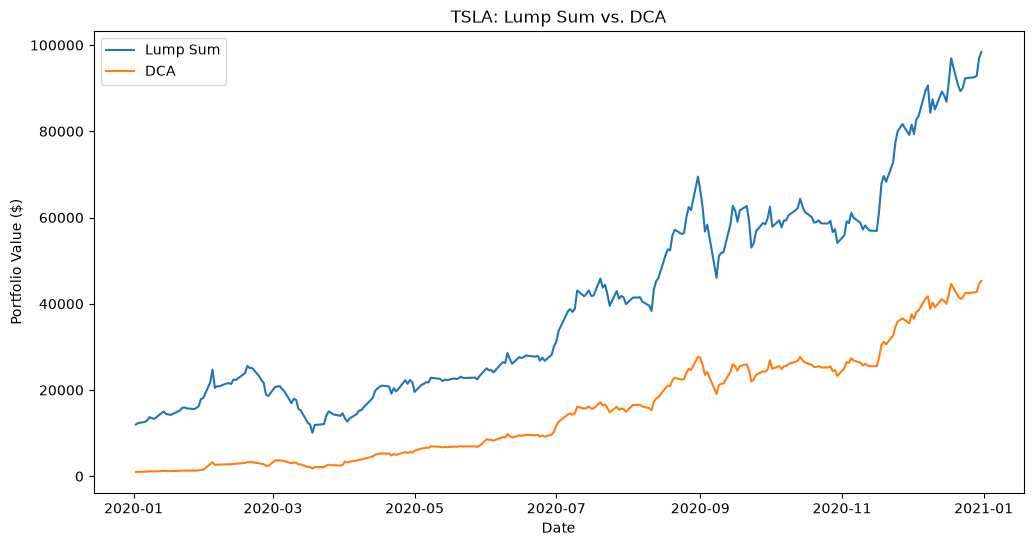

In [33]:
plt.figure(figsize=(12, 6))

plt.plot(lump_sum, label="Lump Sum")
plt.plot(dca, label="DCA")

plt.title("TSLA: Lump Sum vs. DCA")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()

First real test data but its only over 1 year. Will test again with the proper 10 year investment plan 

Hand Calculations: 

DCA: 



Lump-Sum:
  


  